# OptiMatrix Lab: Market Making (Modello Avellaneda-Stoikov)

Simulazione di una strategia di Market Making con quotazione dinamica di Bid e Ask in funzione dell'inventario detenuto, con i parametri della Sezione 4 di Avellaneda & Stoikov (2008), *High-frequency trading in a limit order book*.

* Prezzo di riserva: $r = s - q \gamma \sigma^2 (T-t)$
* Spread ottimale: $\delta^a + \delta^b = \gamma \sigma^2 (T-t) + \frac{2}{\gamma}\ln\left(1 + \frac{\gamma}{k}\right)$
* Mid-price: passeggiata aleatoria $s_{t+dt} = s_t \pm \sigma\sqrt{dt}$
* Esecuzioni: processo di Poisson con intensità $\lambda(\delta) = A e^{-k\delta}$

---
## 1. Simulazione Algoritmica

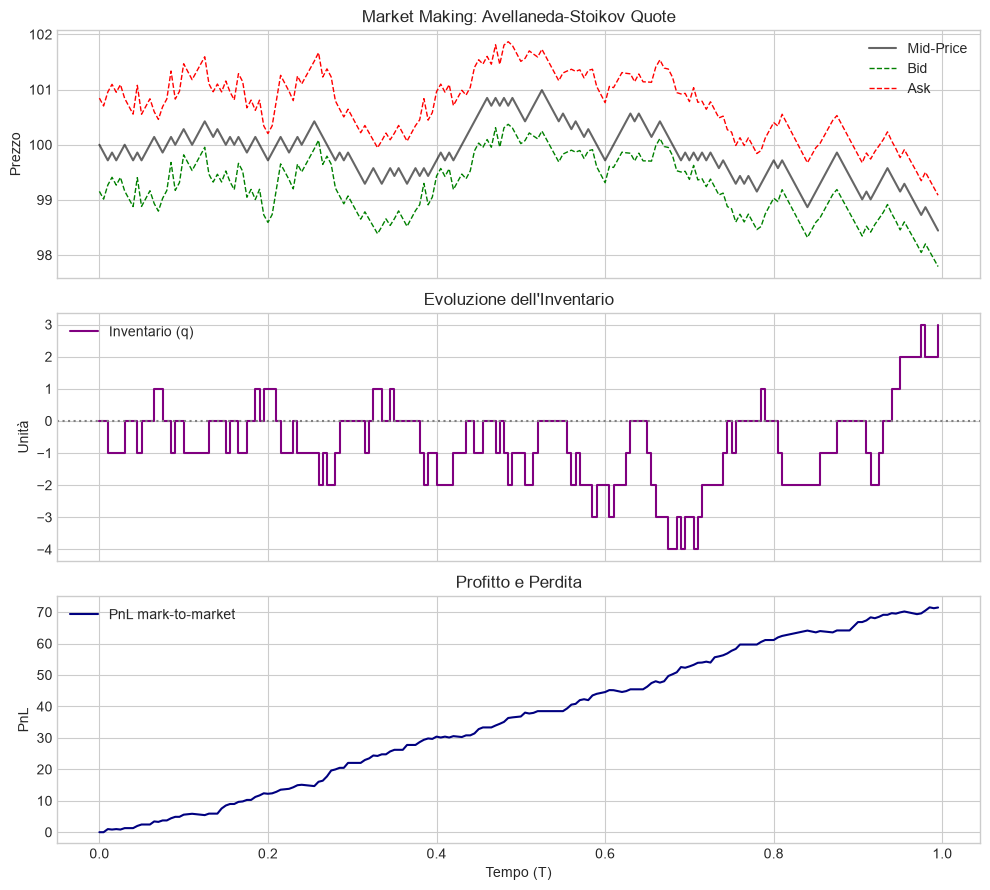

 gamma strategia          spread t=0  PnL medio  std PnL  q medio  std q
  0.01 Inventario (A-S)         1.37      68.35     8.91    -0.04   5.20
  0.01 Simmetrica               1.37      68.26    13.28    -0.03   8.53
   0.1 Inventario (A-S)         1.69      64.90     6.52     0.02   2.89
   0.1 Simmetrica               1.69      67.39    12.90     0.05   8.31
   0.5 Inventario (A-S)         3.15      48.59     5.79     0.08   1.93
   0.5 Simmetrica               3.15      58.32    11.29    -0.02   6.99


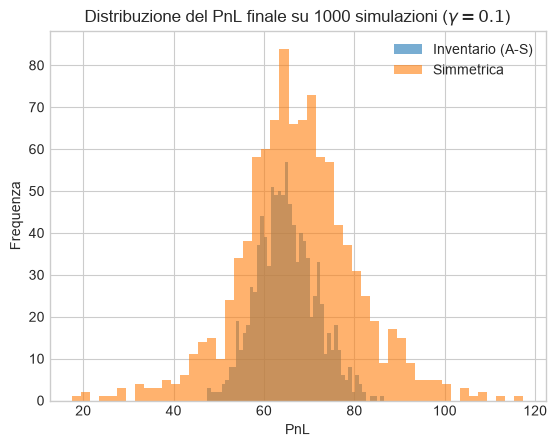

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Parametri della Sezione 4 di Avellaneda & Stoikov (2008)
S0, T, dt = 100.0, 1.0, 0.005
N = int(round(T / dt))
sigma = 2.0                    # volatilità assoluta del mid-price (unità di prezzo per unità di tempo)
k_param, A = 1.5, 140.0
t = np.arange(N + 1) * dt


def simula(n_paths, inventory_aware, gamma=0.1, seed=42):
    """Simula n_paths sessioni di market making e restituisce PnL finale, inventario finale e la prima traiettoria.

    inventory_aware=True  -> quote centrate sul prezzo di riserva r = s - q*gamma*sigma^2*(T-t)
    inventory_aware=False -> quote simmetriche attorno al mid, con lo stesso spread
    In ogni passo ciascun lato viene eseguito con probabilità lambda(delta)*dt = A*exp(-k*delta)*dt
    (al massimo un'esecuzione per lato; se la probabilità supera 1 l'esecuzione è certa).
    """
    rng = np.random.default_rng(seed)
    s = np.full(n_paths, S0)
    q = np.zeros(n_paths)
    cash = np.zeros(n_paths)
    traiettoria = {'mid': [], 'bid': [], 'ask': [], 'q': [], 'pnl': []}

    for i in range(N):
        tau = T - t[i]
        spread = gamma * sigma**2 * tau + (2 / gamma) * np.log(1 + gamma / k_param)
        centro = s - q * gamma * sigma**2 * tau if inventory_aware else s
        bid, ask = centro - spread / 2, centro + spread / 2

        traiettoria['mid'].append(s[0]); traiettoria['bid'].append(bid[0])
        traiettoria['ask'].append(ask[0]); traiettoria['q'].append(q[0])
        traiettoria['pnl'].append(cash[0] + q[0] * s[0])

        delta_b, delta_a = s - bid, ask - s
        fill_bid = rng.random(n_paths) < A * np.exp(-k_param * delta_b) * dt
        fill_ask = rng.random(n_paths) < A * np.exp(-k_param * delta_a) * dt
        q += fill_bid.astype(float) - fill_ask
        cash += np.where(fill_ask, ask, 0.0) - np.where(fill_bid, bid, 0.0)

        # mid-price: passeggiata binomiale +-sigma*sqrt(dt), come nell'articolo
        s = s + sigma * np.sqrt(dt) * np.where(rng.random(n_paths) < 0.5, 1.0, -1.0)

    pnl = cash + q * s           # inventario residuo valutato al mid finale
    traiettoria = {key: np.array(v) for key, v in traiettoria.items()}
    return pnl, q, traiettoria


# Una singola traiettoria della strategia con gestione dell'inventario (gamma = 0.1)
_, _, path = simula(1, inventory_aware=True)
tt = t[:-1]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
ax1.plot(tt, path['mid'], 'k-', alpha=0.6, label='Mid-Price')
ax1.plot(tt, path['bid'], 'g--', lw=1, label='Bid')
ax1.plot(tt, path['ask'], 'r--', lw=1, label='Ask')
ax1.set_title('Market Making: Avellaneda-Stoikov Quote')
ax1.set_ylabel('Prezzo')
ax1.legend()

ax2.step(tt, path['q'], where='post', color='purple', label='Inventario (q)')
ax2.axhline(0, color='gray', linestyle=':')
ax2.set_title("Evoluzione dell'Inventario")
ax2.set_ylabel('Unità')
ax2.legend()

ax3.plot(tt, path['pnl'], color='navy', label='PnL mark-to-market')
ax3.set_title('Profitto e Perdita')
ax3.set_xlabel('Tempo (T)')
ax3.set_ylabel('PnL')
ax3.legend()
plt.tight_layout()
plt.show()

# Confronto Monte Carlo con la strategia simmetrica per tre livelli di avversione al rischio,
# come nelle tabelle dell'articolo. Lo stesso seme per le due strategie (numeri casuali comuni)
# rende il confronto meno rumoroso.
n_sim = 1000
risultati = {}
print(f"{'gamma':>6} {'strategia':<17} {'spread t=0':>11} {'PnL medio':>10} {'std PnL':>8} {'q medio':>8} {'std q':>6}")
for gamma in [0.01, 0.1, 0.5]:
    spread0 = gamma * sigma**2 * T + (2 / gamma) * np.log(1 + gamma / k_param)
    for nome, aware in [('Inventario (A-S)', True), ('Simmetrica', False)]:
        pnl, q_fin, _ = simula(n_sim, aware, gamma=gamma, seed=7)
        risultati[(gamma, nome)] = pnl
        print(f"{gamma:>6} {nome:<17} {spread0:>11.2f} {pnl.mean():>10.2f} {pnl.std():>8.2f} "
              f"{q_fin.mean():>8.2f} {q_fin.std():>6.2f}")

plt.figure()
for nome in ['Inventario (A-S)', 'Simmetrica']:
    plt.hist(risultati[(0.1, nome)], bins=50, alpha=0.6, label=nome)
plt.title(f'Distribuzione del PnL finale su {n_sim} simulazioni ($\\gamma = 0.1$)')
plt.xlabel('PnL')
plt.ylabel('Frequenza')
plt.legend()
plt.show()

## 2. Interpretazione

* La strategia simmetrica guadagna in media quanto o più di quella di Avellaneda-Stoikov, ma accumula inventario: la dispersione dell'inventario finale e del PnL è circa doppia o più.
* La strategia di Avellaneda-Stoikov sposta le quote contro l'inventario (con $q > 0$ abbassa bid e ask per vendere più facilmente), riportando $q$ verso zero e riducendo il rischio.
* Aumentando $\gamma$ lo spread si allarga e la gestione dell'inventario diventa più aggressiva: rischio più basso in cambio di un PnL medio più basso.